In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tqdm.auto import tqdm

In [3]:
import mctpy as mct

In [4]:
rng = np.random.default_rng()

In [5]:
M, dx, dim = 100, 1.0, 2
alpha, Dsigma = 0.1875, 0.043057436 # values for FA model setting dx=1

In [6]:
sigma = -0.01
s = rng.normal(loc=sigma, scale=Dsigma/np.power(dx,dim/2),size=(M,)*dim)
s += sigma - np.mean(s)
print(np.min(s),np.max(s))

-0.17935350057042743 0.15481666232421057


In [7]:
g = mct.beta_scaling_function (lam=0.75, sigma=s, M=M, dim=dim, alpha=alpha, dx=dx, blocks=100, store=True)
g0 = mct.beta_scaling_function (lam=0.75, sigma=sigma, M=1, blocks=100, store=True)

In [8]:
correlators = mct.CorrelatorStack([g,g0])

In [9]:
pbar = tqdm(total=g.blocks+1)
correlators.solve_all(callback=lambda d, bs2, bs, c: pbar.update(1),stop_condition=lambda c:(c.phi_[-1]<-1).all())
pbar.close()

  0%|          | 0/101 [00:00<?, ?it/s]

In [10]:
a, b = mct.util.exponents(g.lambda_)

In [11]:
valid = g.t>0
valid0 = g0.t>0

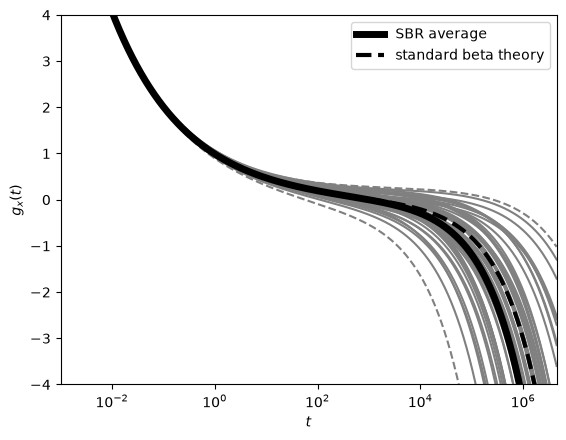

In [12]:
plt.plot(g.t[valid],g.phi[valid].reshape(g.t[valid].shape[0],-1)[:,::2*M],color='gray')
last = g.phi[valid][-1]
min_i = np.unravel_index(np.argmin(last,axis=None),last.shape)
max_i = np.unravel_index(np.argmax(last,axis=None),last.shape)
plt.plot(g.t[valid],g.phi[valid][(...,)+min_i],color='gray',linestyle='dashed')
plt.plot(g.t[valid],g.phi[valid][(...,)+max_i],color='gray',linestyle='dashed')
plt.plot(g.t[valid],np.mean(g.phi[valid].reshape(g.t[valid].shape[0],-1), axis=-1), color='black', linewidth=5,label='SBR average')
plt.plot(g0.t[valid0],g0.phi[valid0,0], color='black', linewidth=3, linestyle='dashed',label='standard beta theory')
plt.xscale('log')
plt.xlim(1e-3,g.t[valid][-1])
plt.ylim(-4,4)
plt.xlabel(r'$t$')
plt.ylabel(r'$g_x(t)$')
plt.legend()
plt.show()

In [13]:
Blam = np.mean(g.phi[valid][-50:,:,:]*np.power(g.t[valid][-50:],-b)[:,None,None],axis=0)

In [14]:
np.mean(Blam),np.std(Blam),np.std(Blam)/np.mean(Blam)

(np.float64(-0.0019684377255668184),
 np.float64(0.0010982859728161328),
 np.float64(-0.5579480410028606))

In [15]:
mct.util.Blambda(g.lambda_)

np.float64(-0.91432265)

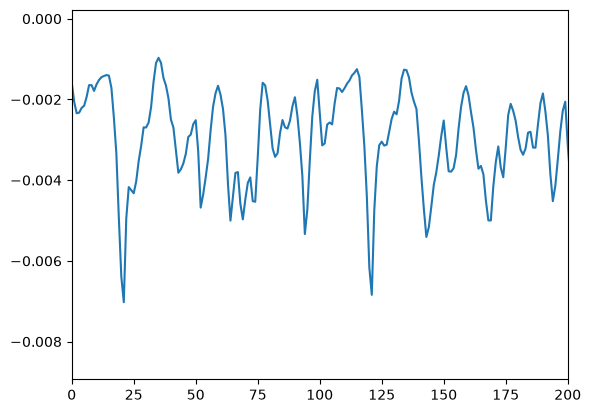

In [16]:
plt.plot(Blam.reshape(-1))
plt.xlim(0,200)
plt.show()

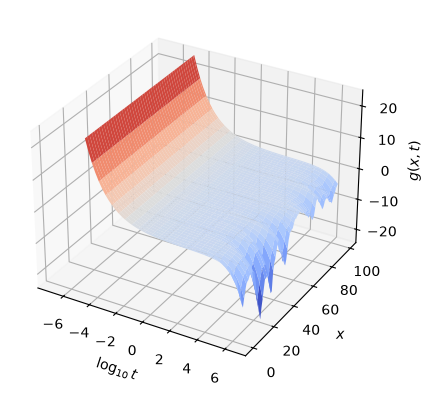

In [17]:
t_, g_  = np.meshgrid(g.t[valid][100::100],np.arange(M),indexing='ij')
z_ = g.phi[valid][100::100,:,0] #* np.power(t_,b)
z_[z_>25] = np.nan
t_.shape,g_.shape,z_.shape
fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))
ax.plot_surface(np.log10(t_), g_, z_, cmap=plt.cm.coolwarm)
ax.set_zlim(top=25)
ax.set_xlabel(r'$\log_{10}t$')
ax.set_ylabel(r'$x$')
ax.set_zlabel(r'$g(x,t)$')
plt.show()

In [18]:
g = mct.beta_scaling_function (lam=0.74, sigma=-s, M=M, dim=dim, alpha=0.2, blocks=100, store=True)
g0 = mct.beta_scaling_function (lam=0.74, sigma=-sigma, M=1, blocks=100, store=True)

In [19]:
correlators = mct.CorrelatorStack([g,g0])

In [20]:
pbar = tqdm(total=g.blocks+1)
correlators.solve_all(callback=lambda d, bs2, bs, c: pbar.update(1),stop_condition=lambda c:False and c==g0 or (c.phi_[-1]<-1).all())
pbar.close()

  0%|          | 0/101 [00:00<?, ?it/s]

In [21]:
valid = g.t>0
valid0 = g0.t>0

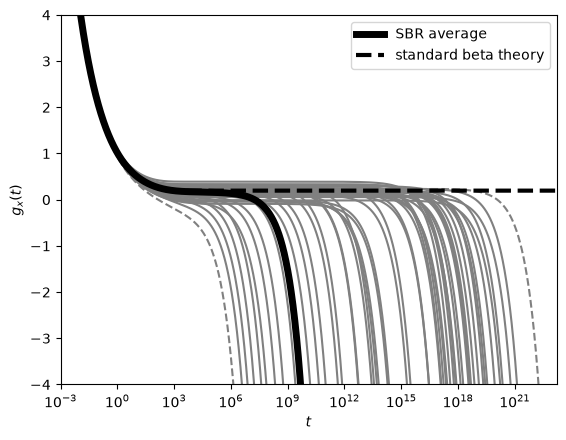

In [22]:
plt.plot(g.t[valid],g.phi[valid].reshape(g.t[valid].shape[0],-1)[:,::2*M],color='gray')
last = g.phi[valid][-1]
min_i = np.unravel_index(np.argmin(last,axis=None),last.shape)
max_i = np.unravel_index(np.argmax(last,axis=None),last.shape)
plt.plot(g.t[valid],g.phi[valid][(...,)+min_i],color='gray',linestyle='dashed')
plt.plot(g.t[valid],g.phi[valid][(...,)+max_i],color='gray',linestyle='dashed')
plt.plot(g.t[valid],np.mean(g.phi[valid].reshape(g.t[valid].shape[0],-1), axis=-1), color='black', linewidth=5,label='SBR average')
plt.plot(g0.t[valid0],g0.phi[valid0,0], color='black', linewidth=3, linestyle='dashed',label='standard beta theory')
plt.xscale('log')
plt.xlim(1e-3,g.t[valid][-1])
plt.ylim(-4,4)
plt.xlabel(r'$t$')
plt.ylabel(r'$g_x(t)$')
plt.legend()
plt.show()

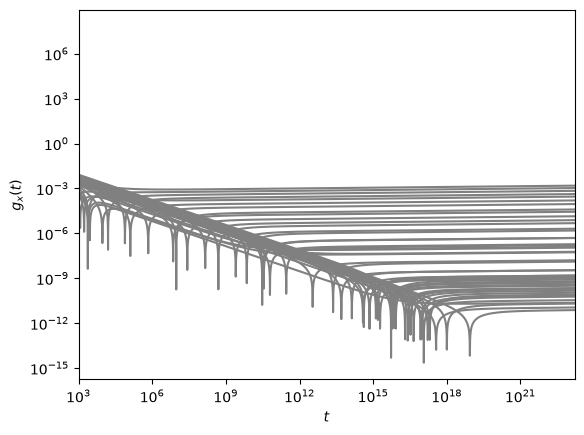

In [23]:
plt.plot(g.t[valid],np.abs(g.phi[valid][:,:,:]*np.power(g.t[valid],-b)[:,None,None]).reshape(g.t[valid].shape[0],-1)[:,::2*M],color='gray')
last = g.phi[valid][-1]
plt.xscale('log')
plt.yscale('log')
plt.xlim(1e3,g.t[valid][-1])
plt.xlabel(r'$t$')
plt.ylabel(r'$g_x(t)$')
plt.show()

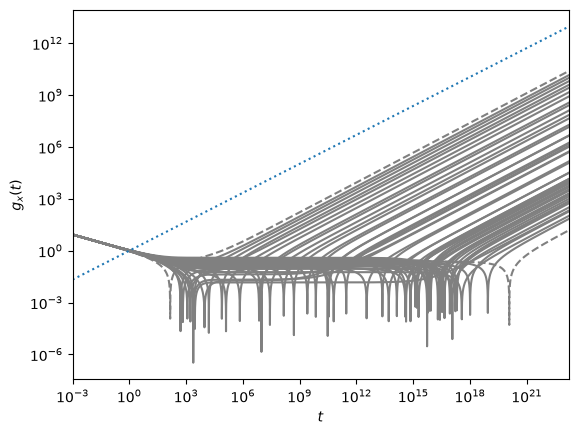

In [24]:
plt.plot(g.t[valid],np.abs(g.phi[valid].reshape(g.t[valid].shape[0],-1)[:,::2*M]),color='gray')
last = g.phi[valid][-1]
min_i = np.unravel_index(np.argmin(last,axis=None),last.shape)
max_i = np.unravel_index(np.argmax(last,axis=None),last.shape)
plt.plot(g.t[valid],np.abs(g.phi[valid][(...,)+min_i]),color='gray',linestyle='dashed')
plt.plot(g.t[valid],np.abs(g.phi[valid][(...,)+max_i]),color='gray',linestyle='dashed')
plt.plot(g.t[valid],np.power(g.t[valid],b),linestyle='dotted')
plt.xscale('log')
plt.yscale('log')
plt.xlim(1e-3,g.t[valid][-1])
plt.xlabel(r'$t$')
plt.ylabel(r'$g_x(t)$')
#plt.legend()
plt.show()

In [25]:
Blamglass = np.mean(g.phi[valid][-50:,:,:]*np.power(g.t[valid][-50:],-b)[:,None,None],axis=0)

In [26]:
np.mean(Blamglass),np.std(Blamglass),np.std(Blamglass)/np.mean(Blamglass)

(np.float64(-2.7463413266927896e-05),
 np.float64(0.00013061659975242482),
 np.float64(-4.7560220750024715))

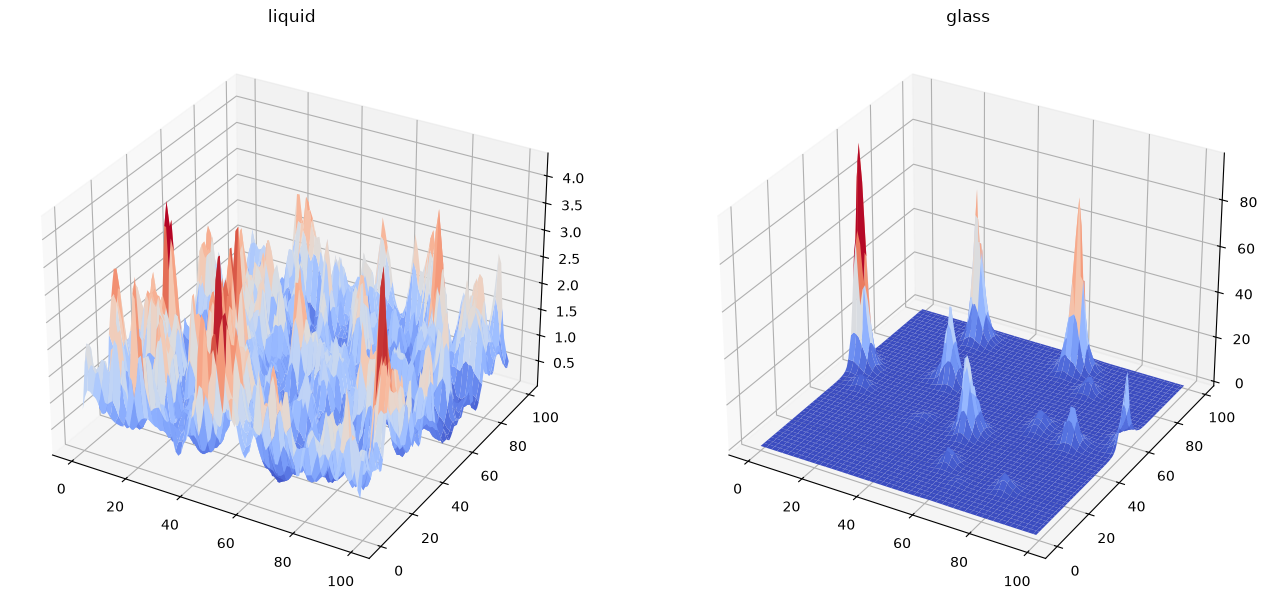

In [27]:
x_, y_  = np.meshgrid(np.arange(M),np.arange(M))
fig, ax = plt.subplots(ncols=2,figsize=(16,12),subplot_kw=dict(projection='3d'))
ax[0].set_title('liquid')
ax[0].plot_surface(x_, y_, Blam/np.mean(Blam), cmap=plt.cm.coolwarm)
ax[1].set_title('glass')
ax[1].plot_surface(x_, y_, Blamglass/np.mean(Blamglass), cmap=plt.cm.coolwarm)
plt.show()

In [28]:
tau_g = g.phi.shape[0] - np.sum(g.phi<-1,axis=0)

In [29]:
np.std(tau_g)/np.mean(tau_g)

np.float64(0.16519182801231685)